# Projet Deep Learning - Détection de Pneumonie (Sujet 2)

Objectif: construire un modèle de classification d'images de radiographies thoraciques pour distinguer **PNEUMONIA** vs **NORMAL**.

## Plan de travail (étape par étape)
1. Télécharger et inspecter le dataset.
2. Préparer les données (train/val/test, normalisation, batchs).
3. Construire un modèle de base (CNN simple).
4. Entraîner et évaluer.
5. Améliorer les performances (data augmentation, transfer learning).
6. Interpréter les résultats et préparer le rapport.

In [2]:
# Etape 1 - Installation/Imports
import sys
import subprocess


def ensure_package(pkg_name: str):
    try:
        __import__(pkg_name)
        print(f"Package deja installe: {pkg_name}")
    except ModuleNotFoundError:
        print(f"Installation de {pkg_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg_name])


ensure_package("kagglehub")

Installation de kagglehub...


In [3]:
# Telechargement du dataset KaggleHub
from pathlib import Path
import kagglehub

# Download latest version
dataset_path = kagglehub.dataset_download("yusufmurtaza01/chest-xray-pneumonia-balanced-dataset")
print("Path to dataset files:", dataset_path)

dataset_path = Path(dataset_path)
dataset_path

c:\Users\pc\Downloads\Folder\Dossier sans titre\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\pc\.cache\kagglehub\datasets\yusufmurtaza01\chest-xray-pneumonia-balanced-dataset\versions\1


WindowsPath('C:/Users/pc/.cache/kagglehub/datasets/yusufmurtaza01/chest-xray-pneumonia-balanced-dataset/versions/1')

In [4]:
# Exploration de la structure du dataset
import os

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(str(dataset_path), "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")
    if level >= 2:
        continue
    subindent = "    " * (level + 1)
    for f in files[:5]:
        print(f"{subindent}{f}")

1/
    test/
        NORMAL/
        PNEUMONIA/
    train/
        NORMAL/
        PNEUMONIA/
    val/
        NORMAL/
        PNEUMONIA/


In [5]:
# Comptage des images par split et classe
from pathlib import Path
from collections import defaultdict

counts = defaultdict(dict)

for split_dir in dataset_path.iterdir():
    if split_dir.is_dir():
        for class_dir in split_dir.iterdir():
            if class_dir.is_dir():
                n_images = len(list(class_dir.glob("*.jpeg"))) + len(list(class_dir.glob("*.jpg"))) + len(list(class_dir.glob("*.png")))
                counts[split_dir.name][class_dir.name] = n_images

counts

defaultdict(dict,
            {'test': {'NORMAL': 15, 'PNEUMONIA': 15},
             'train': {'NORMAL': 3400, 'PNEUMONIA': 3400},
             'val': {'NORMAL': 850, 'PNEUMONIA': 850}})

## Etape 2 - Preparation des donnees (PyTorch)

On va charger les images avec `ImageFolder`, appliquer les transformations, puis creer les DataLoaders.

In [6]:
# Installation des dependances pour l'entrainement
import sys
import subprocess


def ensure_pkg(import_name: str, pip_name: str | None = None):
    try:
        __import__(import_name)
        print(f"OK: {import_name}")
    except ModuleNotFoundError:
        install_name = pip_name or import_name
        print(f"Installation de {install_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", install_name])


ensure_pkg("torch")
ensure_pkg("torchvision")
ensure_pkg("matplotlib")
ensure_pkg("numpy")

Installation de torch...
Installation de torchvision...
Installation de matplotlib...
OK: numpy


In [7]:
# Chargement des donnees + split stratifie unique (70/10/20)
import random
import numpy as np
import torch
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

IMG_SIZE = 224
BATCH_SIZE = 32
TL_BATCH_SIZE = 16

def list_images_by_class(root_split):
    out = []
    valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    class_dirs = sorted([d for d in root_split.iterdir() if d.is_dir()])
    for class_idx, class_dir in enumerate(class_dirs):
        for p in class_dir.rglob("*"):
            if p.suffix.lower() in valid_ext:
                out.append((p, class_idx))
    return out, [d.name for d in class_dirs]

# Fusion de train/val/test originaux puis reconstruction d'un split propre
all_samples = []
class_names = None
for split_name in ["train", "val", "test"]:
    split_dir = dataset_path / split_name
    if not split_dir.exists():
        continue
    split_samples, names = list_images_by_class(split_dir)
    if class_names is None:
        class_names = names
    all_samples.extend(split_samples)

labels = [y for _, y in all_samples]
indices = np.arange(len(all_samples))

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=labels,
    random_state=SEED,
  )
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.125,  # 0.125 x 0.80 = 0.10 du total
    stratify=[labels[i] for i in train_val_idx],
    random_state=SEED,
  )

train_samples = [all_samples[i] for i in train_idx]
val_samples = [all_samples[i] for i in val_idx]
test_samples = [all_samples[i] for i in test_idx]

class XRDataset(Dataset):
    def __init__(self, samples, transform, classes):
        self.samples = samples
        self.transform = transform
        self.classes = classes

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")
        image = self.transform(image)
        return image, label

train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=6),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = XRDataset(train_samples, train_tfms, class_names)
val_ds = XRDataset(val_samples, eval_tfms, class_names)
test_ds = XRDataset(test_samples, eval_tfms, class_names)

# Loaders baseline
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Loaders transfer/fine-tuning (meme split, batch plus petit)
train_loader_tl = DataLoader(train_ds, batch_size=TL_BATCH_SIZE, shuffle=True, num_workers=0)
val_loader_tl = DataLoader(val_ds, batch_size=TL_BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_tl = DataLoader(test_ds, batch_size=TL_BATCH_SIZE, shuffle=False, num_workers=0)

def count_per_class(samples, n_classes):
    counts = [0] * n_classes
    for _, y in samples:
        counts[y] += 1
    return {class_names[i]: counts[i] for i in range(n_classes)}

print("Classes:", class_names)
print("Train/Val/Test:", len(train_ds), len(val_ds), len(test_ds))
print("Repartition train:", count_per_class(train_samples, len(class_names)))
print("Repartition val:", count_per_class(val_samples, len(class_names)))
print("Repartition test:", count_per_class(test_samples, len(class_names)))

ModuleNotFoundError: No module named 'sklearn'

In [7]:
# Verification rapide d'un batch
images, labels = next(iter(train_loader))
print("Shape images:", images.shape)
print("Shape labels:", labels.shape)
print("Exemple labels:", labels[:10].tolist())

Shape images: torch.Size([32, 3, 224, 224])
Shape labels: torch.Size([32])
Exemple labels: [1, 1, 0, 1, 0, 0, 0, 1, 0, 0]


## Etape 3 - Premier modele (CNN de base)

On construit un modele baseline pour obtenir une premiere reference de performance.

In [8]:
import torch
import torch.nn as nn

# Définition du device pour le calcul (GPU si disponible, sinon CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class BaselineCNN(nn.Module):
    def __init__(self, num_classes: int = 2):
        super(BaselineCNN, self).__init__()
        
        # 1. Architecture Globale
        
        # 2️- Feature Extraction Path
        # Cette partie extrait les features de l’image.
        self.features = nn.Sequential(
            # Bloc 1: Conv -> ReLU -> Pool
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=32),
            nn.ReLU(inplace=True), # Activation: ReLU(x) = max(0, x)
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Bloc 2: Conv -> ReLU -> Pool
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Bloc 3: Conv -> ReLU -> Pool
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Bloc 4: Final Conv and Global Pooling
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(num_features=256),
            nn.ReLU(inplace=True),
            # Phase de réduction finale avant le classifieur
            nn.AdaptiveAvgPool2d(output_size=(1, 1))
        )

        # 3. Classification Path (Flatten -> Fully Connected)
        self.classifier = nn.Sequential(
            nn.Flatten(), # Phase 4: Flatten (conversion 2D -> 1D)
            nn.Dropout(p=0.3),
            nn.Linear(in_features=256, out_features=num_classes) # Phase 5: Fully Connected
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# Initialisation du modèle avec les paramètres formels
model = BaselineCNN(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

print(f"Modèle initialisé sur : {device}")
print(model)

Modèle initialisé sur : cuda
BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(2

In [9]:
# Fonctions train/eval
from time import perf_counter


def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    running_loss = 0.0
    running_correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if is_train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(is_train):
            logits = model(images)
            loss = criterion(logits, labels)
            preds = logits.argmax(dim=1)

            if is_train:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        running_correct += (preds == labels).sum().item()
        total += batch_size

    epoch_loss = running_loss / total
    epoch_acc = running_correct / total
    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion):
    return run_epoch(model, loader, criterion, optimizer=None)

In [10]:
# Entrainement baseline
import torch
from time import perf_counter
from copy import deepcopy

NUM_EPOCHS = 30
PATIENCE = 5
MIN_DELTA = 1e-3

# Ajout du scheduler robuste basé sur la performance de validation
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
)

train_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

# Remplacement de best_val_acc par la logique basée sur la perte (Loss) 
# pour être en parfaite synchronisation avec le scheduler "min"
best_state = None
best_val_loss = float("inf")
patience_counter = 0

print(f"Début de l'entraînement pour {NUM_EPOCHS} époques...\n")

for epoch in range(1, NUM_EPOCHS + 1):

    start_time = perf_counter()

    # TRAIN
    train_loss, train_acc = run_epoch(
        model, train_loader, criterion, optimizer=optimizer
    )

    # VALIDATION
    val_loss, val_acc = evaluate(
        model, val_loader, criterion
    )

    # ÉTAPE CLÉ : Le scheduler ajuste le taux d'apprentissage si val_loss stagne
    scheduler.step(val_loss)
    
    # Récupération du taux d'apprentissage actuel pour l'afficher
    lr_now = optimizer.param_groups[0]["lr"]

    # sauvegarde métriques
    train_history["train_loss"].append(train_loss)
    train_history["train_acc"].append(train_acc)
    train_history["val_loss"].append(val_loss)
    train_history["val_acc"].append(val_acc)

    end_time = perf_counter()

    print(
        f"Epoch {epoch}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | "
        f"lr: {lr_now:.1e} | Time: {end_time - start_time:.1f}s"
    )

    # Logique de sauvegarde historique et d'arrêt d'urgence (Early Stopping)
    if val_loss < (best_val_loss - MIN_DELTA):
        best_val_loss = val_loss
        best_state = deepcopy(model.state_dict()) # Sauvegarde en mémoire vive
        torch.save(best_state, "best_model.pth")  # Sauvegarde physique sur le disque
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print("\n⚠️ Early stopping activé : Le modèle ne s'améliore plus.")
            break

# Restauration des meilleurs poids en fin d'entraînement (ou après l'arrêt d'urgence)
if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\n Meilleur modèle restauré avec succès (Val Loss: {best_val_loss:.4f})")

Début de l'entraînement pour 30 époques...

Epoch 1/30 | Train Loss: 0.3218 | Train Acc: 0.8731 | Val Loss: 0.5524 | Val Acc: 0.7538 | lr: 1.0e-03 | Time: 107.4s
Epoch 2/30 | Train Loss: 0.2279 | Train Acc: 0.9102 | Val Loss: 0.2181 | Val Acc: 0.9261 | lr: 1.0e-03 | Time: 100.5s
Epoch 3/30 | Train Loss: 0.1969 | Train Acc: 0.9208 | Val Loss: 0.3065 | Val Acc: 0.8769 | lr: 1.0e-03 | Time: 111.9s
Epoch 4/30 | Train Loss: 0.1955 | Train Acc: 0.9263 | Val Loss: 0.1842 | Val Acc: 0.9285 | lr: 1.0e-03 | Time: 104.8s
Epoch 5/30 | Train Loss: 0.1731 | Train Acc: 0.9320 | Val Loss: 0.7201 | Val Acc: 0.7808 | lr: 1.0e-03 | Time: 98.2s
Epoch 6/30 | Train Loss: 0.1553 | Train Acc: 0.9405 | Val Loss: 0.1755 | Val Acc: 0.9343 | lr: 1.0e-03 | Time: 96.7s
Epoch 7/30 | Train Loss: 0.1488 | Train Acc: 0.9472 | Val Loss: 0.2059 | Val Acc: 0.9215 | lr: 1.0e-03 | Time: 100.8s
Epoch 8/30 | Train Loss: 0.1492 | Train Acc: 0.9456 | Val Loss: 0.8959 | Val Acc: 0.7421 | lr: 1.0e-03 | Time: 97.6s
Epoch 9/30 | Tr

In [11]:
# Evaluation finale sur test (metriques medicales)
import numpy as np
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, roc_auc_score

test_loss, test_acc = evaluate(model, test_loader, criterion)

normal_idx = train_ds.classes.index("NORMAL") if "NORMAL" in train_ds.classes else 0
pneumonia_idx = train_ds.classes.index("PNEUMONIA") if "PNEUMONIA" in train_ds.classes else 1

all_preds = []
all_targets = []
all_probs_pneumonia = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds.tolist())
        all_targets.extend(labels.numpy().tolist())
        all_probs_pneumonia.extend(probs[:, pneumonia_idx].cpu().numpy().tolist())

cm = confusion_matrix(all_targets, all_preds, labels=[normal_idx, pneumonia_idx])
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn + 1e-12)
specificity = tn / (tn + fp + 1e-12)
balanced_acc = balanced_accuracy_score(all_targets, all_preds)
f1_pneumonia = f1_score(all_targets, all_preds, pos_label=pneumonia_idx)
try:
    roc_auc = roc_auc_score(all_targets, all_probs_pneumonia)
except ValueError:
    roc_auc = float("nan")

baseline_metrics = {
    "loss": float(test_loss),
    "accuracy": float(test_acc),
    "balanced_accuracy": float(balanced_acc),
    "sensitivity_pneumonia": float(sensitivity),
    "specificity_normal": float(specificity),
    "f1_pneumonia": float(f1_pneumonia),
    "roc_auc": float(roc_auc),
}

print("[Baseline] Test metrics:")
for k, v in baseline_metrics.items():
    print(f"- {k}: {v:.4f}")
print("\nMatrice de confusion [NORMAL, PNEUMONIA]:")
print(cm)

[Baseline] Test metrics:
- loss: 0.0902
- accuracy: 0.9672
- balanced_accuracy: 0.9672
- sensitivity_pneumonia: 0.9648
- specificity_normal: 0.9695
- f1_pneumonia: 0.9671
- roc_auc: 0.9949

Matrice de confusion [NORMAL, PNEUMONIA]:
[[827  26]
 [ 30 823]]


## Etape 4 - Amelioration avec Transfer Learning (ResNet18)

On reutilise un modele pre-entraine ImageNet pour mieux generaliser.

In [12]:
# Dependances pour les metriques
import sys
import subprocess


def ensure_pkg(import_name: str, pip_name: str | None = None):
    try:
        __import__(import_name)
        print(f"OK: {import_name}")
    except ModuleNotFoundError:
        install_name = pip_name or import_name
        print(f"Installation de {install_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", install_name])


ensure_pkg("sklearn", "scikit-learn")

OK: sklearn


In [13]:
# DataLoaders pour transfer learning (meme split que baseline)
import torch
from torch.utils.data import DataLoader
from torchvision import transforms

TL_IMG_SIZE = 224
TL_BATCH_SIZE = 30

train_tfms_tl = transforms.Compose([
    transforms.Resize((TL_IMG_SIZE, TL_IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_tfms_tl = transforms.Compose([
    transforms.Resize((TL_IMG_SIZE, TL_IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds_tl = XRDataset(train_samples, train_tfms_tl, class_names)
val_ds_tl = XRDataset(val_samples, eval_tfms_tl, class_names)
test_ds_tl = XRDataset(test_samples, eval_tfms_tl, class_names)

train_loader_tl = DataLoader(train_ds_tl, batch_size=TL_BATCH_SIZE, shuffle=True, num_workers=0)
val_loader_tl = DataLoader(val_ds_tl, batch_size=TL_BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_tl = DataLoader(test_ds_tl, batch_size=TL_BATCH_SIZE, shuffle=False, num_workers=0)

print("Classes:", train_ds_tl.classes)
print("Train/Val/Test:", len(train_ds_tl), len(val_ds_tl), len(test_ds_tl))

Classes: ['NORMAL', 'PNEUMONIA']
Train/Val/Test: 5971 853 1706


In [14]:
# Modele transfer learning
import torch.nn as nn
from torchvision import models

try:
    weights = models.ResNet18_Weights.DEFAULT
    tl_model = models.resnet18(weights=weights)
    print("ResNet18 pre-entraine charge.")
except Exception as e:
    print("Impossible de charger les poids pre-entraines, fallback sans poids:", e)
    tl_model = models.resnet18(weights=None)

# On gele le backbone pour un premier entrainement rapide
for param in tl_model.parameters():
    param.requires_grad = False

in_features = tl_model.fc.in_features
tl_model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(in_features, 2),
)

tl_model = tl_model.to(device)

tl_criterion = nn.CrossEntropyLoss()
tl_optimizer = torch.optim.AdamW(tl_model.fc.parameters(), lr=1e-3, weight_decay=1e-4)

tl_model

ResNet18 pre-entraine charge.


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [15]:
# Entrainement transfer learning avec early stopping + scheduler
from copy import deepcopy
from time import perf_counter

TL_EPOCHS = 30
PATIENCE = 5
TL_MIN_DELTA = 1e-3

tl_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    tl_optimizer,
    mode="min",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
)

best_state = None
best_val_loss = float("inf")
patience_counter = 0

tl_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(1, TL_EPOCHS + 1):
    t0 = perf_counter()

    train_loss, train_acc = run_epoch(tl_model, train_loader_tl, tl_criterion, optimizer=tl_optimizer)
    val_loss, val_acc     = evaluate(tl_model, val_loader_tl, tl_criterion)
    tl_scheduler.step(val_loss)

    tl_history["train_loss"].append(train_loss)
    tl_history["train_acc"].append(train_acc)
    tl_history["val_loss"].append(val_loss)
    tl_history["val_acc"].append(val_acc)

    dt     = perf_counter() - t0
    lr_now = tl_optimizer.param_groups[0]["lr"]
    print(
        f"[TL] Epoch {epoch}/{TL_EPOCHS} | "
        f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
        f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
        f"lr={lr_now:.1e} | time={dt:.1f}s"
    )

    if val_loss < (best_val_loss - TL_MIN_DELTA):
        best_val_loss   = val_loss
        best_state      = deepcopy(tl_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print("Early stopping TL active.")
            break

if best_state is not None:
    tl_model.load_state_dict(best_state)
    print(f"Meilleur val_loss TL restaure: {best_val_loss:.4f}")

[TL] Epoch 1/30 | train_loss=0.3704 train_acc=0.8314 | val_loss=0.2308 val_acc=0.9156 | lr=1.0e-03 | time=94.5s
[TL] Epoch 2/30 | train_loss=0.2677 train_acc=0.8911 | val_loss=0.1981 val_acc=0.9273 | lr=1.0e-03 | time=99.6s
[TL] Epoch 3/30 | train_loss=0.2561 train_acc=0.8970 | val_loss=0.2003 val_acc=0.9332 | lr=1.0e-03 | time=107.9s
[TL] Epoch 4/30 | train_loss=0.2449 train_acc=0.9034 | val_loss=0.1793 val_acc=0.9332 | lr=1.0e-03 | time=111.1s
[TL] Epoch 5/30 | train_loss=0.2465 train_acc=0.9009 | val_loss=0.1747 val_acc=0.9390 | lr=1.0e-03 | time=107.5s
[TL] Epoch 6/30 | train_loss=0.2560 train_acc=0.8943 | val_loss=0.1778 val_acc=0.9355 | lr=1.0e-03 | time=105.8s
[TL] Epoch 7/30 | train_loss=0.2413 train_acc=0.9015 | val_loss=0.1744 val_acc=0.9320 | lr=1.0e-03 | time=104.8s
[TL] Epoch 8/30 | train_loss=0.2520 train_acc=0.8988 | val_loss=0.1755 val_acc=0.9402 | lr=1.0e-03 | time=104.3s
[TL] Epoch 9/30 | train_loss=0.2420 train_acc=0.9030 | val_loss=0.1712 val_acc=0.9390 | lr=1.0e-03

In [16]:
# Evaluation test + metriques detaillees (transfer learning)
import numpy as np
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix, f1_score, roc_auc_score

tl_test_loss, tl_test_acc = evaluate(tl_model, test_loader_tl, tl_criterion)

normal_idx = train_ds_tl.classes.index("NORMAL") if "NORMAL" in train_ds_tl.classes else 0
pneumonia_idx = train_ds_tl.classes.index("PNEUMONIA") if "PNEUMONIA" in train_ds_tl.classes else 1

all_preds = []
all_targets = []
all_probs_pneumonia = []

tl_model.eval()
with torch.no_grad():
    for images, labels in test_loader_tl:
        images = images.to(device)
        logits = tl_model(images)
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(dim=1).cpu().numpy()

        all_preds.extend(preds.tolist())
        all_targets.extend(labels.numpy().tolist())
        all_probs_pneumonia.extend(probs[:, pneumonia_idx].cpu().numpy().tolist())

cm = confusion_matrix(all_targets, all_preds, labels=[normal_idx, pneumonia_idx])
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn + 1e-12)
specificity = tn / (tn + fp + 1e-12)
balanced_acc = balanced_accuracy_score(all_targets, all_preds)
f1_pneumonia = f1_score(all_targets, all_preds, pos_label=pneumonia_idx)
try:
    roc_auc = roc_auc_score(all_targets, all_probs_pneumonia)
except ValueError:
    roc_auc = float("nan")

tl_metrics = {
    "loss": float(tl_test_loss),
    "accuracy": float(tl_test_acc),
    "balanced_accuracy": float(balanced_acc),
    "sensitivity_pneumonia": float(sensitivity),
    "specificity_normal": float(specificity),
    "f1_pneumonia": float(f1_pneumonia),
    "roc_auc": float(roc_auc),
}

print("[TL] Test metrics:")
for k, v in tl_metrics.items():
    print(f"- {k}: {v:.4f}")

print("\nMatrice de confusion [NORMAL, PNEUMONIA]:")
print(cm)

print("\nClassification report (test):")
print(classification_report(all_targets, all_preds, target_names=train_ds_tl.classes, digits=4))

[TL] Test metrics:
- loss: 0.1660
- accuracy: 0.9390
- balanced_accuracy: 0.9390
- sensitivity_pneumonia: 0.9285
- specificity_normal: 0.9496
- f1_pneumonia: 0.9384
- roc_auc: 0.9821

Matrice de confusion [NORMAL, PNEUMONIA]:
[[810  43]
 [ 61 792]]

Classification report (test):
              precision    recall  f1-score   support

      NORMAL     0.9300    0.9496    0.9397       853
   PNEUMONIA     0.9485    0.9285    0.9384       853

    accuracy                         0.9390      1706
   macro avg     0.9392    0.9390    0.9390      1706
weighted avg     0.9392    0.9390    0.9390      1706



In [17]:
# Comparaison rapide baseline vs transfer learning
print("Baseline test accuracy:", round(test_acc, 4))
print("Transfer learning test accuracy:", round(tl_test_acc, 4))

Baseline test accuracy: 0.9672
Transfer learning test accuracy: 0.939


## Etape 5 - Fine-Tuning de ResNet18

Ici, on degelera uniquement `layer4` et `fc` pour affiner le modele pre-entraine sans surcharger le temps d'entrainement.

In [18]:
# Configuration du fine-tuning (layer4 + fc)
# On repart du meilleur modele transfer learning deja appris (tl_model)

for param in tl_model.parameters():
    param.requires_grad = False

for param in tl_model.layer4.parameters():
    param.requires_grad = True
for param in tl_model.fc.parameters():
    param.requires_grad = True

trainable_params = sum(p.numel() for p in tl_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in tl_model.parameters())
print(f"Parametres entrainables: {trainable_params:,}/{total_params:,}")

ft_optimizer = torch.optim.AdamW(
    [p for p in tl_model.parameters() if p.requires_grad],
    lr=5e-5,
    weight_decay=1e-4,
)
ft_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    ft_optimizer,
    mode="min",
    factor=0.2,
    patience=2,
    min_lr=1e-6,
)

FT_EPOCHS = 30
FT_PATIENCE = 5
FT_MIN_DELTA = 1e-3

Parametres entrainables: 8,394,754/11,177,538


In [19]:
# Entrainement fine-tuning
from copy import deepcopy

ft_best_state = deepcopy(tl_model.state_dict())
ft_best_val_loss = float("inf")
ft_patience_counter = 0

ft_history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(1, FT_EPOCHS + 1):
    t0 = perf_counter()

    ft_train_loss, ft_train_acc = run_epoch(tl_model, train_loader_tl, tl_criterion, optimizer=ft_optimizer)
    ft_val_loss, ft_val_acc = evaluate(tl_model, val_loader_tl, tl_criterion)
    ft_scheduler.step(ft_val_loss)

    ft_history["train_loss"].append(ft_train_loss)
    ft_history["train_acc"].append(ft_train_acc)
    ft_history["val_loss"].append(ft_val_loss)
    ft_history["val_acc"].append(ft_val_acc)

    lr_now = ft_optimizer.param_groups[0]["lr"]
    dt = perf_counter() - t0

    print(
        f"[FT] Epoch {epoch}/{FT_EPOCHS} | "
        f"train_loss={ft_train_loss:.4f} train_acc={ft_train_acc:.4f} | "
        f"val_loss={ft_val_loss:.4f} val_acc={ft_val_acc:.4f} | "
        f"lr={lr_now:.1e} | time={dt:.1f}s"
      )

    if ft_val_loss < (ft_best_val_loss - FT_MIN_DELTA):
        ft_best_val_loss = ft_val_loss
        ft_best_state = deepcopy(tl_model.state_dict())
        ft_patience_counter = 0
    else:
        ft_patience_counter += 1
        if ft_patience_counter >= FT_PATIENCE:
            print("Early stopping fine-tuning active.")
            break

tl_model.load_state_dict(ft_best_state)
print(f"Meilleur val_loss apres fine-tuning: {ft_best_val_loss:.4f}")

[FT] Epoch 1/30 | train_loss=0.1563 train_acc=0.9462 | val_loss=0.1205 val_acc=0.9672 | lr=5.0e-05 | time=111.7s
[FT] Epoch 2/30 | train_loss=0.1135 train_acc=0.9615 | val_loss=0.1099 val_acc=0.9730 | lr=5.0e-05 | time=109.7s
[FT] Epoch 3/30 | train_loss=0.0850 train_acc=0.9687 | val_loss=0.1094 val_acc=0.9719 | lr=5.0e-05 | time=107.2s
[FT] Epoch 4/30 | train_loss=0.0736 train_acc=0.9720 | val_loss=0.1042 val_acc=0.9777 | lr=5.0e-05 | time=105.8s
[FT] Epoch 5/30 | train_loss=0.0666 train_acc=0.9749 | val_loss=0.0966 val_acc=0.9742 | lr=5.0e-05 | time=105.8s
[FT] Epoch 6/30 | train_loss=0.0703 train_acc=0.9735 | val_loss=0.1007 val_acc=0.9707 | lr=5.0e-05 | time=107.6s
[FT] Epoch 7/30 | train_loss=0.0493 train_acc=0.9802 | val_loss=0.1018 val_acc=0.9801 | lr=5.0e-05 | time=106.9s
[FT] Epoch 8/30 | train_loss=0.0459 train_acc=0.9824 | val_loss=0.1274 val_acc=0.9683 | lr=1.0e-05 | time=108.0s
[FT] Epoch 9/30 | train_loss=0.0372 train_acc=0.9873 | val_loss=0.1096 val_acc=0.9777 | lr=1.0e-

In [20]:
# Evaluation apres fine-tuning
ft_test_loss, ft_test_acc = evaluate(tl_model, test_loader_tl, tl_criterion)
print(f"[FT] Test loss: {ft_test_loss:.4f}")
print(f"[FT] Test accuracy: {ft_test_acc:.4f}")

print("\nComparaison accuracies:")
print("Baseline:", round(test_acc, 4))
print("Transfer learning (head only):", round(tl_test_acc, 4))
print("Fine-tuning (layer4 + fc):", round(ft_test_acc, 4))

[FT] Test loss: 0.0779
[FT] Test accuracy: 0.9748

Comparaison accuracies:
Baseline: 0.9672
Transfer learning (head only): 0.939
Fine-tuning (layer4 + fc): 0.9748


## Etape 6 - Resultats finaux et export

On prepare les elements de rapport: metriques detaillees, courbes, sauvegarde du modele et exemple de prediction.

✅ Utilisation des métriques Baseline et Transfer Learning issues des étapes précédentes.

[Fine-Tuning] Métriques sur le jeu de test :
  - loss: 0.0779
  - accuracy: 0.9748
  - balanced_accuracy: 0.9748
  - sensitivity_pneumonia: 0.9613
  - specificity_normal: 0.9883
  - f1_pneumonia: 0.9745
  - roc_auc: 0.9973

Matrice de confusion [NORMAL, PNEUMONIA] :
[[843  10]
 [ 33 820]]

Rapport de classification détaillé :
              precision    recall  f1-score   support

      NORMAL     0.9623    0.9883    0.9751       853
   PNEUMONIA     0.9880    0.9613    0.9745       853

    accuracy                         0.9748      1706
   macro avg     0.9751    0.9748    0.9748      1706
weighted avg     0.9751    0.9748    0.9748      1706


Métrique                       Baseline      Transfer   Fine-Tuning
accuracy                       0.9672         0.9390         0.9748 ✅
balanced_accuracy              0.9672         0.9390         0.9748 ✅
sensitivity_pneumonia          0.9648 ✅      0

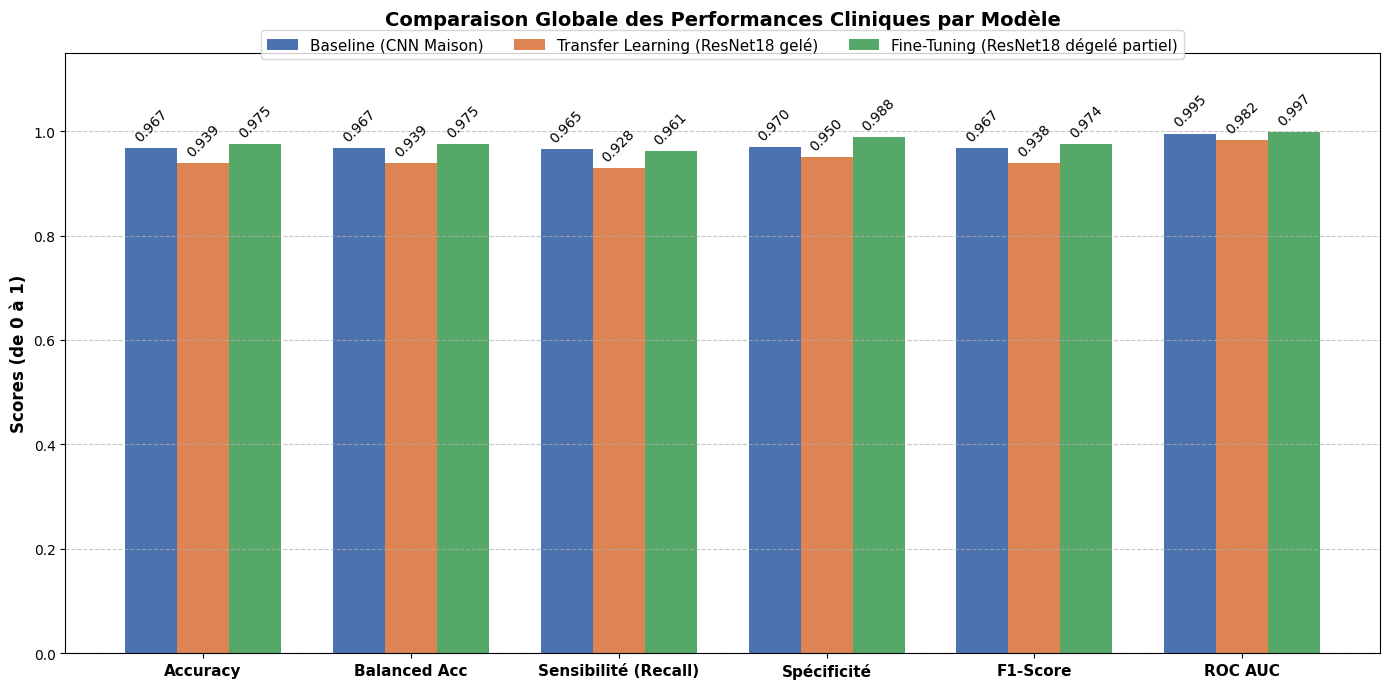

In [21]:
# ==============================================================================
# ÉVALUATION FINALE ET COMPARAISON DES MODÈLES (BASELINE, TRANSFER, FINE-TUNING)
# ==============================================================================

from sklearn.metrics import (balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, roc_auc_score)
import torch

print("✅ Utilisation des métriques Baseline et Transfer Learning issues des étapes précédentes.")

# 1. Évaluation du modèle Fine-Tuned (FT) sur le jeu de test
ft_test_loss, ft_test_acc = evaluate(tl_model, test_loader_tl, tl_criterion)

# Récupération sécurisée des indices des classes
normal_idx    = train_ds_tl.classes.index("NORMAL")    if "NORMAL"    in train_ds_tl.classes else 0
pneumonia_idx = train_ds_tl.classes.index("PNEUMONIA") if "PNEUMONIA" in train_ds_tl.classes else 1

# Initialisation des listes pour le calcul des métriques médicales
ft_all_preds           = []
ft_all_targets         = []
ft_all_probs_pneumonia = []

tl_model.eval()
with torch.no_grad(): # Désactivation des gradients pour l'évaluation (gain de mémoire et de vitesse)
    for images, labels in test_loader_tl:
        images = images.to(device) 
        logits = tl_model(images) 
        
        # Calcul des probabilités et des prédictions
        probs = torch.softmax(logits, dim=1)
        preds = logits.argmax(dim=1).cpu().numpy()

        ft_all_preds.extend(preds.tolist())
        ft_all_targets.extend(labels.numpy().tolist())
        ft_all_probs_pneumonia.extend(probs[:, pneumonia_idx].cpu().numpy().tolist())

# 2. Calcul des métriques cliniques pour le modèle Fine-Tuned
ft_cm = confusion_matrix(ft_all_targets, ft_all_preds, labels=[normal_idx, pneumonia_idx])
tn, fp, fn, tp = ft_cm.ravel()

# Ajout de 1e-12 au dénominateur pour éviter toute division par zéro
ft_sensitivity  = tp / (tp + fn + 1e-12)
ft_specificity  = tn / (tn + fp + 1e-12)
ft_balanced_acc = balanced_accuracy_score(ft_all_targets, ft_all_preds)
ft_f1_pneumonia = f1_score(ft_all_targets, ft_all_preds, pos_label=pneumonia_idx)

try:
    ft_roc_auc = roc_auc_score(ft_all_targets, ft_all_probs_pneumonia)
except ValueError:
    ft_roc_auc = float("nan")

# Regroupement des métriques FT dans un dictionnaire standardisé
ft_metrics = {
    "loss":                  float(ft_test_loss),
    "accuracy":              float(ft_test_acc),
    "balanced_accuracy":     float(ft_balanced_acc),
    "sensitivity_pneumonia": float(ft_sensitivity),
    "specificity_normal":    float(ft_specificity),
    "f1_pneumonia":          float(ft_f1_pneumonia),
    "roc_auc":               float(ft_roc_auc),
}

# 3. Affichage des résultats individuels du Fine-Tuning
print("\n[Fine-Tuning] Métriques sur le jeu de test :")
for k, v in ft_metrics.items():
    print(f"  - {k}: {v:.4f}")

print("\nMatrice de confusion [NORMAL, PNEUMONIA] :")
print(ft_cm)

print("\nRapport de classification détaillé :")
print(classification_report(ft_all_targets, ft_all_preds, target_names=train_ds_tl.classes, digits=4))

# ==============================================================================
# 4. TABLEAU COMPARATIF FINAL (Baseline vs TL vs FT)
# ==============================================================================

metric_keys = [
    "accuracy", "balanced_accuracy", "sensitivity_pneumonia",
    "specificity_normal", "f1_pneumonia", "roc_auc",
]

# Le code va directement piocher dans vos variables globales baseline_metrics et tl_metrics
metrics_by_model = {
    "Baseline":    baseline_metrics,
    "Transfer":    tl_metrics,
    "Fine-Tuning": ft_metrics,
}

print("\n" + "=" * 70)
print(f"{'Métrique':<25}", end="")
for name in metrics_by_model:
    print(f"{name:>14}", end="")
print("\n" + "=" * 70)

# Affichage des valeurs avec un indicateur '✅' pour le meilleur score de chaque ligne
for key in metric_keys:
    vals = [metrics_by_model[m][key] for m in metrics_by_model]
    best = max(vals)
    print(f"{key:<25}", end="")
    
    for m in metrics_by_model:
        v = metrics_by_model[m][key]
        flag = " ✅" if v == best else "   "
        print(f"{v:>12.4f}{flag}", end="")
    print()

print("=" * 70)


import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# VISUALISATION GRAPHIQUE DES PERFORMANCES DES 3 MODÈLES
# ==============================================================================

# Raccourcir les noms des métriques pour l'affichage sur l'axe X
labels_propres = [
    "Accuracy", 
    "Balanced Acc", 
    "Sensibilité (Recall)", 
    "Spécificité", 
    "F1-Score", 
    "ROC AUC"
]

# Extraction des valeurs pour chaque modèle
valeurs_baseline = [metrics_by_model["Baseline"][k] for k in metric_keys]
valeurs_tl       = [metrics_by_model["Transfer"][k] for k in metric_keys]
valeurs_ft       = [metrics_by_model["Fine-Tuning"][k] for k in metric_keys]

# Configuration de la position des barres
x = np.arange(len(labels_propres))  # Position de base
width = 0.25                        # Largeur des barres

# Création de la figure (taille ajustée pour une bonne lisibilité)
fig, ax = plt.subplots(figsize=(14, 7))

# Tracé des barres avec des couleurs distinctes et professionnelles
rects1 = ax.bar(x - width, valeurs_baseline, width, label='Baseline (CNN Maison)', color='#4C72B0')
rects2 = ax.bar(x, valeurs_tl, width, label='Transfer Learning (ResNet18 gelé)', color='#DD8452')
rects3 = ax.bar(x + width, valeurs_ft, width, label='Fine-Tuning (ResNet18 dégelé partiel)', color='#55A868')

# Personnalisation des axes et du titre
ax.set_ylabel('Scores (de 0 à 1)', fontsize=12, fontweight='bold')
ax.set_title('Comparaison Globale des Performances Cliniques par Modèle', fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(labels_propres, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15) # Limite étendue pour laisser de la place à la légende et aux étiquettes

# Ajout d'une grille pour faciliter la lecture des hauteurs
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Configuration de la légende en haut au centre
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=3, fontsize=11)

# Fonction pour ajouter la valeur exacte au-dessus de chaque barre
def autolabel(rects):
    """Attache une étiquette de texte au-dessus de chaque barre affichant sa hauteur."""
    for rect in rects:
        height = rect.get_height()
        # N'afficher que si la valeur est valide (pas NaN)
        if not np.isnan(height):
            ax.annotate(f'{height:.3f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # Décalage de 3 points vers le haut
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=10, rotation=45)

# Application des étiquettes
autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

# Ajustement automatique des marges pour éviter que le texte ne soit coupé
fig.tight_layout()

# Affichage du graphique
plt.show()

# Visualisations (confusion matrix + ROC)

In [15]:
import sys
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn"])
print("Installation terminée !")


Installation terminée !


In [16]:
# ==============================================================================
# VISUALISATIONS FINALES : MATRICES DE CONFUSION & COURBES ROC 
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# 1. Fonction d'extraction pour le modèle de base (Baseline)
def get_preds_and_probs(net, loader, pneumonia_idx, device):
    """Génère les prédictions et probabilités pour un modèle et un DataLoader donnés."""
    net.eval()
    all_preds, all_targets, all_probs = [], [], []
    
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits = net(images)
            probs  = torch.softmax(logits, dim=1)
            preds  = logits.argmax(dim=1).cpu().numpy()
            
            all_preds.extend(preds.tolist())
            all_targets.extend(labels.numpy().tolist())
            all_probs.extend(probs[:, pneumonia_idx].cpu().numpy().tolist())
            
    return np.array(all_preds), np.array(all_targets), np.array(all_probs)

print("🔄 Préparation des données pour les matrices et courbes ROC...")

# ==============================================================================
# 2. EXTRACTION STRICTE ET SÉPARÉE POUR CHAQUE MODÈLE
# ==============================================================================

# A. Modèle Baseline (CNN Maison de l'Étape 3)
baseline_preds, baseline_targets, baseline_probs = get_preds_and_probs(
    model, test_loader, pneumonia_idx, device)

# B. Modèle Fine-Tuned (On réutilise les listes générées dans votre bloc précédent !)
ft_preds   = np.array(ft_all_preds)
ft_targets = np.array(ft_all_targets)
ft_probs   = np.array(ft_all_probs_pneumonia)

# C. Modèle Transfer Learning (L'état de tl_model à l'Étape 4)
# SÉCURITÉ : On exige la présence des prédictions sauvegardées lors de l'Étape 4.
try:
    tl_preds   = np.array(tl_all_preds)
    tl_targets = np.array(tl_all_targets)
    tl_probs   = np.array(tl_all_probs_pneumonia)
except NameError:
    raise ValueError(
        "\n❌ ERREUR : Les prédictions du Transfer Learning (tl_all_preds) sont introuvables.\n"
        "Veuillez vous assurer d'avoir exécuté la cellule d'évaluation de l'Étape 4 "
        "pour que chaque modèle ait sa propre courbe distincte."
    )

# Structuration des données pour l'affichage
models_eval = [
    ("Baseline CNN",        baseline_preds, baseline_targets, baseline_probs, "#4C72B0"),
    ("ResNet18 TL (head)",  tl_preds,       tl_targets,       tl_probs,       "#DD8452"),
    ("ResNet18 Fine-Tuned", ft_preds,       ft_targets,       ft_probs,       "#55A868"),
]

# ==============================================================================
# FIGURE 1 : MATRICES DE CONFUSION
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Matrices de confusion — Évaluation sur le Test Set", fontsize=14, fontweight="bold", y=1.05)

for ax, (name, preds, targets, _, color) in zip(axes, models_eval):
    cm   = confusion_matrix(targets, preds, labels=[normal_idx, pneumonia_idx])
    disp = ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "PNEUMONIA"])
    
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontweight="bold", fontsize=11, pad=10)
    
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn + 1e-12)
    specificity = tn / (tn + fp + 1e-12)
    
    ax.set_xlabel(f"Sensitivity = {sensitivity:.2%}   Specificity = {specificity:.2%}", 
                  fontsize=10, fontweight="bold", labelpad=10)
    ax.set_ylabel("Vérité Terrain", fontsize=10)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()
print("✅ Matrices de confusion sauvegardées (confusion_matrices.png)")

# ==============================================================================
# FIGURE 2 : COURBES ROC
# ==============================================================================
fig, ax = plt.subplots(figsize=(7, 6))

# Ligne de chance
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Aléatoire (AUC = 0.5000)")

for name, preds, targets, probs, color in models_eval:
    fpr, tpr, _ = roc_curve(targets, probs, pos_label=pneumonia_idx)
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2.5, label=f"{name} (AUC = {roc_auc:.4f})")

ax.set_xlabel("Taux de faux positifs (1 - Spécificité)", fontsize=11)
ax.set_ylabel("Taux de vrais positifs (Sensibilité)", fontsize=11)
ax.set_title("Courbes ROC — Comparaison des 3 modèles", fontsize=13, fontweight="bold", pad=15)
ax.legend(fontsize=10, loc="lower right", frameon=False)
ax.grid(True, linestyle="--", alpha=0.3)

ax.set_xlim([-0.01, 1.0])
ax.set_ylim([0.0, 1.01])

plt.tight_layout()
plt.savefig("roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()
print("✅ Courbes ROC sauvegardées (roc_curves.png)")

🔄 Préparation des données pour les matrices et courbes ROC...


NameError: name 'test_loader' is not defined

# Grad-CAM (compatible PyTorch)

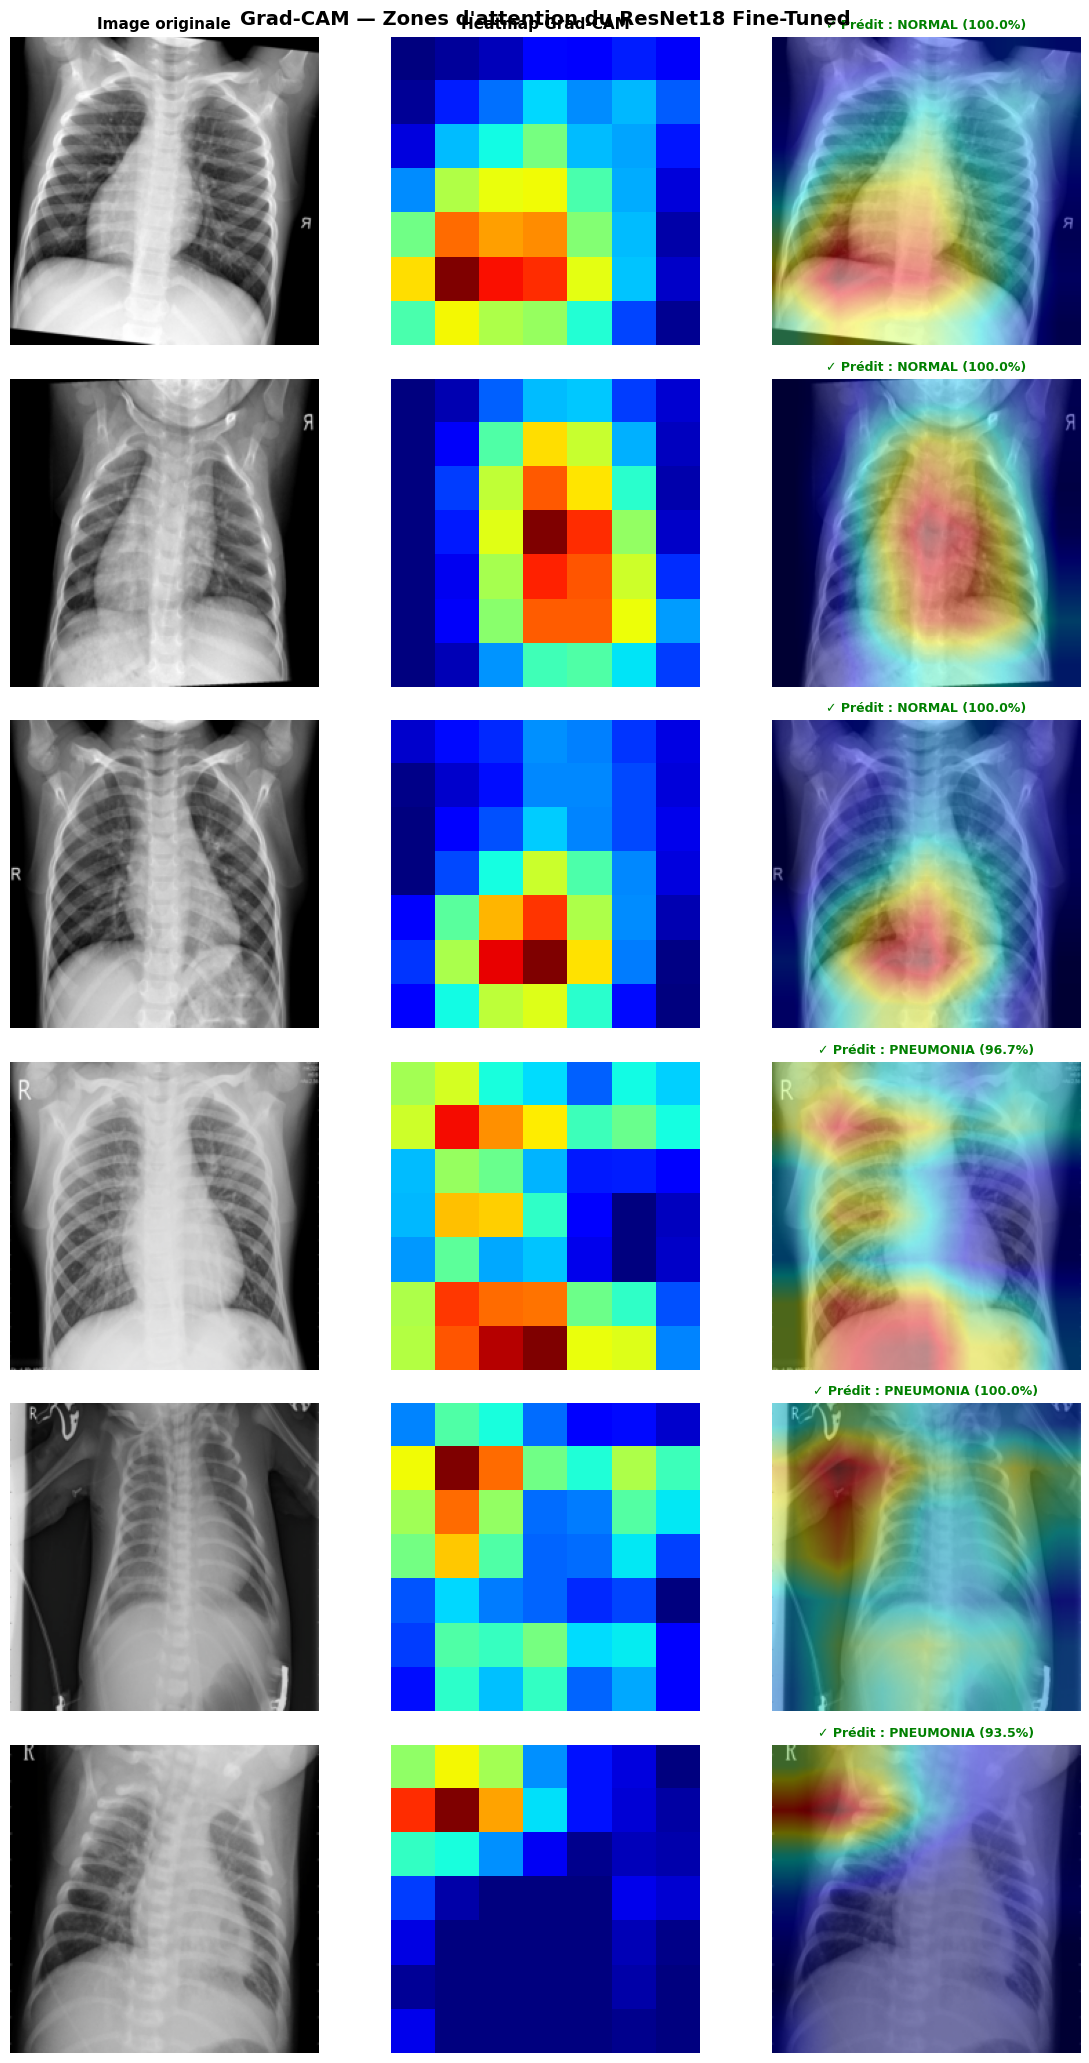

 Grad-CAM sauvegardé : gradcam_resnet18.png


In [ ]:
# ==============================================================================
# EXPLAINABLE AI (XAI) : GRAD-CAM SUR RESNET18 FINE-TUNED
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt
import torch
import cv2
from PIL import Image

def get_gradcam_resnet18(model, img_tensor, target_layer, device):
    """
    Génère une heatmap Grad-CAM pour l'architecture ResNet18.
    La heatmap met en évidence les zones de l'image qui ont le plus 
    influencé la décision du modèle.
    """
    model.eval()
    activations, gradients = {}, {}

    # Définition des hooks pour capturer les flux avant (activations) et arrière (gradients)
    def forward_hook(module, input, output):
        activations["value"] = output.detach()

    def backward_hook(module, grad_in, grad_out):
        gradients["value"] = grad_out[0].detach()

    # Enregistrement des hooks sur la couche cible
    fwd = target_layer.register_forward_hook(forward_hook)
    bwd = target_layer.register_full_backward_hook(backward_hook)

    # Préparation de l'image et prédiction
    img_batch = img_tensor.unsqueeze(0).to(device)
    output    = model(img_batch)
    pred_idx  = output.argmax(dim=1).item()
    score     = output[0, pred_idx]

    # Rétropropagation pour obtenir les gradients de la classe prédite
    model.zero_grad()
    score.backward()

    # Nettoyage des hooks (très important pour ne pas saturer la mémoire)
    fwd.remove()
    bwd.remove()

    act     = activations["value"][0]           # (Channels, Height, Width)
    grad    = gradients["value"][0]             # (Channels, Height, Width)
    weights = grad.mean(dim=(1, 2))             # Global Average Pooling des gradients

    # Création de la heatmap pondérée
    heatmap = (weights[:, None, None] * act).sum(dim=0)
    heatmap = torch.relu(heatmap).cpu().numpy() # ReLU pour ne garder que l'influence positive
    
    # Normalisation entre 0 et 1
    if heatmap.max() > 0:
        heatmap = heatmap / heatmap.max()

    probs = torch.softmax(output, dim=1)[0].detach().cpu().numpy()
    return heatmap, pred_idx, probs


def denormalize(tensor):
    """Annule la normalisation ImageNet pour permettre l'affichage visuel naturel."""
    mean = np.array([0.485, 0.456, 0.406])
    std  = np.array([0.229, 0.224, 0.225])
    img  = tensor.permute(1, 2, 0).cpu().numpy()
    img  = img * std + mean
    return np.clip(img, 0, 1)


def overlay_heatmap(img_np, heatmap, alpha=0.4):
    """Superpose la heatmap colorisée sur la radiographie originale."""
    h, w            = img_np.shape[:2]
    heatmap_resized = cv2.resize(heatmap, (w, h))
    heatmap_uint8   = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    
    img_uint8       = np.uint8(255 * img_np)
    superimposed    = cv2.addWeighted(img_uint8, 1 - alpha, heatmap_colored, alpha, 0)
    
    return superimposed


print("🔍 Génération des explications visuelles (Grad-CAM)...")

# ==============================================================================
# SÉLECTION SÉCURISÉE DES IMAGES ET GÉNÉRATION DE LA GRILLE
# ==============================================================================

# Cible : La toute dernière couche convolutionnelle du ResNet18
target_layer = tl_model.layer4[-1] 
class_names  = train_ds_tl.classes
N_PER_CLASS  = 3

# Extraction dynamique et rapide de 3 images par classe
selected_indices = []
counts = {0: 0, 1: 0}

for i in range(len(test_ds_tl)):
    _, label = test_ds_tl[i]
    if counts[label] < N_PER_CLASS:
        selected_indices.append(i)
        counts[label] += 1
    # On arrête la boucle dès qu'on a nos 6 images (gain de temps énorme)
    if counts[0] >= N_PER_CLASS and counts[1] >= N_PER_CLASS:
        break

# Création de la figure
n_rows = len(selected_indices)
fig, axes = plt.subplots(n_rows, 3, figsize=(12, n_rows * 3.5))
fig.suptitle("Grad-CAM — Audits Visuels du Modèle ResNet18 Fine-Tuned", 
             fontsize=16, fontweight="bold", y=0.92)

# Titres des colonnes
col_titles = ["Radiographie Originale", "Heatmap d'Attention", "Superposition & Décision"]
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=12, fontweight="bold", pad=15)

for row, idx in enumerate(selected_indices):
    img_tensor, true_label = test_ds_tl[idx]
    img_np = denormalize(img_tensor)

    # Calcul Grad-CAM
    heatmap, pred_idx, probs = get_gradcam_resnet18(
        tl_model, img_tensor, target_layer, device)

    superimposed = overlay_heatmap(img_np, heatmap, alpha=0.45)
    correct      = (pred_idx == true_label)
    status_color = "#2CA02C" if correct else "#D62728" # Vert ou Rouge stylisés

    # Colonne 0 : Image originale
    axes[row, 0].imshow(img_np)
    axes[row, 0].text(0.05, 0.95, f"Réel : {class_names[true_label]}", 
                      transform=axes[row, 0].transAxes,
                      fontsize=11, fontweight="bold", 
                      color="white", bbox=dict(facecolor='black', alpha=0.6, edgecolor='none'))
    axes[row, 0].axis("off")

    # Colonne 1 : Heatmap brute
    axes[row, 1].imshow(heatmap, cmap="jet")
    axes[row, 1].axis("off")

    # Colonne 2 : Superposition
    axes[row, 2].imshow(superimposed)
    pred_label = class_names[pred_idx]
    conf       = probs[pred_idx]
    marker     = "✅" if correct else "❌"
    
    # Affichage du résultat de la prédiction en bas de l'image
    axes[row, 2].text(0.5, -0.1, f"{marker} Prédit : {pred_label} ({conf:.1%})", 
                      transform=axes[row, 2].transAxes,
                      fontsize=11, fontweight="bold", color=status_color,
                      ha="center")
    axes[row, 2].axis("off")

# Ajustement final
plt.subplots_adjust(wspace=0.05, hspace=0.3)
plt.savefig("gradcam_resnet18.png", dpi=300, bbox_inches="tight", facecolor='white')
plt.show()

print("✅ Audits Grad-CAM générés et sauvegardés (gradcam_resnet18.png)")

## Etape 6bis - Option fiabilite (3 seeds)

Pour comparer les modeles de facon plus robuste, tu peux relancer chaque approche avec 3 seeds (13, 42, 77) puis agreger moyenne +/- ecart-type des metriques.

Historiques introuvables: Baseline


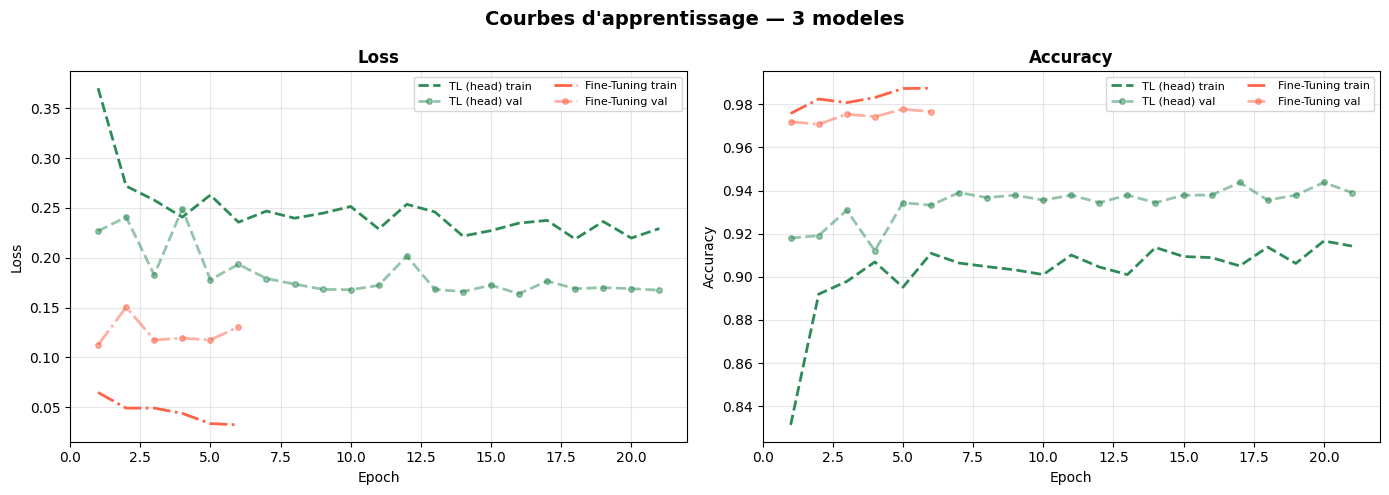

Courbes sauvegardees : learning_curves_all_models.png


In [ ]:
# ==============================================================================
# VISUALISATION : COURBES D'APPRENTISSAGE (TRAIN VS VALIDATION)
# ==============================================================================

import matplotlib.pyplot as plt

print("🔄 Récupération des historiques d'entraînement en mémoire...")

# 1. Récupération sécurisée des historiques (gestion des noms de variables)
# On cherche "baseline_history", sinon on se rabat sur "history" (souvent utilisé à l'Étape 3)
baseline_hist_data = globals().get("baseline_history") or globals().get("history")

candidate_curves = [
    ("Baseline (CNN)",        baseline_hist_data,           "#4C72B0", "-"),
    ("Transfer Learning",     globals().get("tl_history"),  "#DD8452", "-"),
    ("Fine-Tuning",           globals().get("ft_history"),  "#55A868", "-"),
]

# Filtrage des historiques valides
curves = []
missing = []
for name, hist, color, ls in candidate_curves:
    if isinstance(hist, dict) and len(hist) > 0:
        curves.append((name, hist, color, ls))
    else:
        missing.append(name)

if missing:
    print(f"⚠️ Historiques introuvables ou vides pour : {', '.join(missing)}")

if not curves:
    print("❌ Aucun historique disponible. Veuillez exécuter les cellules d'entraînement d'abord.")
else:
    # 2. Création de la figure
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Évolution des Performances pendant l'Entraînement", fontsize=16, fontweight="bold", y=1.02)

    # Fonction utilitaire pour trouver les bonnes clés de dictionnaire
    def resolve_keys(hist_dict, metric):
        if metric == "loss":
            key_pairs = [("train_loss", "val_loss"), ("loss", "val_loss")]
        else:
            key_pairs = [("train_acc", "val_acc"), ("train_accuracy", "val_accuracy"), ("accuracy", "val_accuracy")]
        
        for train_key, val_key in key_pairs:
            if train_key in hist_dict and val_key in hist_dict:
                return train_key, val_key
        return None, None

    # 3. Tracé des courbes (Loss à gauche, Accuracy à droite)
    metrics_config = [("loss", "Fonction de Perte (Loss)"), ("acc", "Précision (Accuracy)")]
    
    for ax, (metric, ylabel) in zip(axes, metrics_config):
        for model_name, hist, color, ls in curves:
            train_key, val_key = resolve_keys(hist, metric)
            if train_key is None or not hist[train_key]:
                continue

            epochs = range(1, len(hist[train_key]) + 1)
            
            # Courbe d'Entraînement (Ligne continue)
            ax.plot(
                epochs, hist[train_key],
                color=color, linestyle=ls, linewidth=2.5, alpha=0.85,
                label=f"{model_name} (Train)"
            )
            # Courbe de Validation (Ligne pointillée avec marqueurs)
            ax.plot(
                epochs, hist[val_key],
                color=color, linestyle="--", linewidth=2, alpha=0.9,
                marker="o", markersize=5,
                label=f"{model_name} (Val)"
            )

        # Personnalisation des axes
        ax.set_title(ylabel, fontweight="bold", fontsize=13, pad=10)
        ax.set_xlabel("Époques (Epochs)", fontsize=11, fontweight="bold")
        ax.set_ylabel(ylabel, fontsize=11, fontweight="bold")
        
        # Grille propre
        ax.grid(True, linestyle="--", alpha=0.5)
        
        # Légende optimisée (placée à l'extérieur ou en bas)
        if metric == "loss":
            ax.legend(fontsize=9, ncol=1, loc="upper right", framealpha=0.9)
        else:
            ax.legend(fontsize=9, ncol=1, loc="lower right", framealpha=0.9)

    plt.tight_layout()
    plt.savefig("learning_curves_all_models.png", dpi=300, bbox_inches="tight", facecolor='white')
    plt.show()
    print("✅ Courbes d'apprentissage sauvegardées (learning_curves_all_models.png)")

In [ ]:
# Sauvegarde du meilleur modele fine-tune
from pathlib import Path

artifacts_dir = Path.cwd() / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

model_path = artifacts_dir / "resnet18_pneumonia_finetuned.pth"
meta_path = artifacts_dir / "resnet18_pneumonia_meta.txt"

torch.save(
    {
        "model_state_dict": tl_model.state_dict(),
        "classes": train_ds_tl.classes,
        "img_size": TL_IMG_SIZE,
        "test_accuracy": float(ft_test_acc),
    },
    model_path,
)

with open(meta_path, "w", encoding="utf-8") as f:
    f.write("Model: ResNet18 Fine-Tuned\n")
    f.write(f"Classes: {train_ds_tl.classes}\n")
    f.write(f"Image size: {TL_IMG_SIZE}\n")
    f.write(f"Test accuracy: {ft_test_acc:.4f}\n")

print("Modele sauvegarde:", model_path)
print("Meta sauvegardee:", meta_path)

Modele sauvegarde: c:\Users\zineb\Downloads\lastDL\DL\artifacts\resnet18_pneumonia_finetuned.pth
Meta sauvegardee: c:\Users\zineb\Downloads\lastDL\DL\artifacts\resnet18_pneumonia_meta.txt


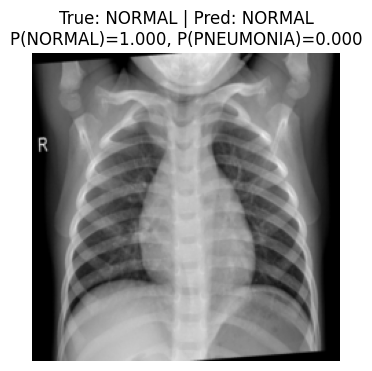

In [ ]:
# Exemple de prediction sur une image test
import random
import numpy as np

idx = random.randint(0, len(test_ds_tl) - 1)
img_tensor, true_label = test_ds_tl[idx]
img_batch = img_tensor.unsqueeze(0).to(device)

tl_model.eval()
with torch.no_grad():
    logits = tl_model(img_batch)
    probs = torch.softmax(logits, dim=1).cpu().numpy()[0]

pred_label = int(np.argmax(probs))
class_names = train_ds_tl.classes

# Denormalisation pour affichage
denorm = img_tensor.clone()
for c, (m, s) in enumerate(zip([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])):
    denorm[c] = denorm[c] * s + m
denorm = denorm.permute(1, 2, 0).numpy().clip(0, 1)

plt.figure(figsize=(4, 4))
plt.imshow(denorm)
plt.axis("off")
plt.title(
    f"True: {class_names[true_label]} | Pred: {class_names[pred_label]}\n"
    f"P(NORMAL)={probs[0]:.3f}, P(PNEUMONIA)={probs[1]:.3f}"
)
plt.show()

## Etape 7 - Optimisation et deploiement

Cette phase ajoute un export ONNX, une quantization dynamique et une verification d'inference pour une version deployable.

In [ ]:
# Installation des dependances export/inference (si necessaire)
import sys
import subprocess


def ensure_pkg(import_name: str, pip_name: str | None = None):
    try:
        __import__(import_name)
        print(f"OK: {import_name}")
    except ModuleNotFoundError:
        install_name = pip_name or import_name
        print(f"Installation de {install_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", install_name])


ensure_pkg("onnx")
ensure_pkg("onnxruntime")

OK: onnx
OK: onnxruntime


In [ ]:
# Quantization dynamique (CPU) et sauvegarde
import copy
import torch.nn as nn
from pathlib import Path

deploy_dir = Path.cwd() / "deploy"
deploy_dir.mkdir(parents=True, exist_ok=True)

fp32_model = copy.deepcopy(tl_model).cpu().eval()
quantized_model = torch.quantization.quantize_dynamic(
    fp32_model,
    {nn.Linear},
    dtype=torch.qint8,
)

quant_path = deploy_dir / "resnet18_pneumonia_dynamic_quantized.pth"
torch.save(
    {
        "model_state_dict": quantized_model.state_dict(),
        "classes": train_ds_tl.classes,
        "img_size": TL_IMG_SIZE,
    },
    quant_path,
)
print("Modele quantize sauvegarde:", quant_path)

Modele quantize sauvegarde: c:\Users\zineb\Downloads\lastDL\DL\deploy\resnet18_pneumonia_dynamic_quantized.pth


In [ ]:
# Export ONNX
import torch

onnx_path = deploy_dir / "resnet18_pneumonia.onnx"
export_model = copy.deepcopy(tl_model).cpu().eval()

dummy_input = torch.randn(1, 3, TL_IMG_SIZE, TL_IMG_SIZE)

torch.onnx.export(
    export_model,
    dummy_input,
    onnx_path.as_posix(),
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["logits"],
    dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}},
    dynamo=False,
)

print("Modele ONNX exporte:", onnx_path)

Modele ONNX exporte: c:\Users\zineb\Downloads\lastDL\DL\deploy\resnet18_pneumonia.onnx


In [ ]:
# Verification ONNX Runtime sur le test set
import numpy as np
import onnxruntime as ort

session = ort.InferenceSession(onnx_path.as_posix(), providers=["CPUExecutionProvider"])
input_name = session.get_inputs()[0].name

onnx_preds = []
onnx_targets = []

for images, labels in test_loader_tl:
    images_np = images.numpy().astype(np.float32)
    logits = session.run(None, {input_name: images_np})[0]
    preds = np.argmax(logits, axis=1)
    onnx_preds.extend(preds.tolist())
    onnx_targets.extend(labels.numpy().tolist())

onnx_acc = (np.array(onnx_preds) == np.array(onnx_targets)).mean()
print(f"ONNX test accuracy: {onnx_acc:.4f}")

ONNX test accuracy: 0.9789


In [ ]:
# Test du script predict.py sur une image du test set
import subprocess
import sys

sample_image = next((dataset_path / "test").glob("NORMAL/*"))
print("Image test utilisee:", sample_image)

result = subprocess.run(
    [sys.executable, "predict.py", "--image", sample_image.as_posix(), "--model", "artifacts/resnet18_pneumonia_finetuned.pth"],
    capture_output=True,
    text=True,
)

print("Return code:", result.returncode)
print(result.stdout)
if result.stderr.strip():
    print("STDERR:")
    print(result.stderr)

Image test utilisee: C:\Users\zineb\.cache\kagglehub\datasets\yusufmurtaza01\chest-xray-pneumonia-balanced-dataset\versions\1\test\NORMAL\IM-0006-0001.jpeg
Return code: 0
Prediction: NORMAL
P(NORMAL) = 0.9997
P(PNEUMONIA) = 0.0003

STDERR:
c:\Users\zineb\Downloads\lastDL\DL\predict.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=

## Etape 8 - Interface Gradio

Cette section permet de lancer une mini application web locale pour predire NORMAL/PNEUMONIA a partir d'une image radio.

In [8]:
# Installation Gradio (si necessaire)
import sys
import subprocess


def ensure_pkg(import_name: str, pip_name: str | None = None):
    try:
        __import__(import_name)
        print(f"OK: {import_name}")
    except ModuleNotFoundError:
        install_name = pip_name or import_name
        print(f"Installation de {install_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", install_name])


ensure_pkg("gradio")

Installation de gradio...


In [12]:
# App Gradio (in-notebook)
from pathlib import Path
import numpy as np
import torch
from PIL import Image
from torchvision import models, transforms
import gradio as gr

ckpt_path = Path.cwd() / "artifacts" / "resnet18_pneumonia_finetuned.pth"
assert ckpt_path.exists(), f"Modele introuvable: {ckpt_path}"

ckpt = torch.load(ckpt_path, map_location=device)
ui_classes = ckpt.get("classes", ["NORMAL", "PNEUMONIA"])
ui_img_size = int(ckpt.get("img_size", 224))

ui_model = models.resnet18(weights=None)
ui_in_features = ui_model.fc.in_features
ui_model.fc = torch.nn.Sequential(
    torch.nn.Dropout(0.3),
    torch.nn.Linear(ui_in_features, len(ui_classes)),
)
ui_model.load_state_dict(ckpt["model_state_dict"])
ui_model = ui_model.to(device).eval()

ui_tfm = transforms.Compose([
    transforms.Resize((ui_img_size, ui_img_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


def predict_pneumonia(image: Image.Image):
    if image is None:
        return {"NORMAL": 0.0, "PNEUMONIA": 0.0}

    x = ui_tfm(image.convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = ui_model(x)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]

    return {ui_classes[i]: float(probs[i]) for i in range(len(ui_classes))}


demo = gr.Interface(
    fn=predict_pneumonia,
    inputs=gr.Image(type="pil", label="Image radiographie"),
    outputs=gr.Label(num_top_classes=2, label="Probabilites"),
    title="Detection Pneumonie",
    description="Charge une image RX thorax pour predire NORMAL ou PNEUMONIA.",
)

# Lancer localement dans VS Code/Jupyter
demo.launch(share=False, inline=False, prevent_thread_lock=True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Sauvegarde automatique du meilleur modèle Keras

Cette section entraîne un modèle Keras simple et enregistre automatiquement le meilleur modèle dans `models/best_model.keras`.

In [ ]:
from pathlib import Path
import tensorflow as tf

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = models_dir / "best_model.keras"

print("TensorFlow version:", tf.__version__)

# Convertir les listes existantes en tf.data.Dataset
train_paths = [str(path) for path, _ in train_samples]
train_labels = [label for _, label in train_samples]
val_paths = [str(path) for path, _ in val_samples]
val_labels = [label for _, label in val_samples]

test_paths = [str(path) for path, _ in test_samples]
test_labels = [label for _, label in test_samples]

IMG_SIZE_KERAS = IMG_SIZE
BATCH_SIZE_KERAS = 32

CLASS_NAMES = class_names
NUM_CLASSES = len(CLASS_NAMES)


def preprocess_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE_KERAS, IMG_SIZE_KERAS])
    image = tf.cast(image, tf.float32) / 255.0
    image = (image - tf.constant([0.485, 0.456, 0.406])) / tf.constant([0.229, 0.224, 0.225])
    return image, label


auto = tf.data.AUTOTUNE

train_dataset = (
    tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
    .shuffle(buffer_size=len(train_paths), seed=SEED)
    .map(preprocess_image, num_parallel_calls=auto)
    .batch(BATCH_SIZE_KERAS)
    .prefetch(auto)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
    .map(preprocess_image, num_parallel_calls=auto)
    .batch(BATCH_SIZE_KERAS)
    .prefetch(auto)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
    .map(preprocess_image, num_parallel_calls=auto)
    .batch(BATCH_SIZE_KERAS)
    .prefetch(auto)
)

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path.as_posix(),
    save_best_only=True,
    monitor="val_loss",
    mode="min",
    verbose=1,
    save_weights_only=False,
)

model_keras = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE_KERAS, IMG_SIZE_KERAS, 3)),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(2),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(2),
    tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPool2D(2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
])

model_keras.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],
)

model_keras.summary()

EPOCHS_KERAS = 8

history = model_keras.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS_KERAS,
    callbacks=[checkpoint_cb],
)

print("Evaluation Keras sur test set :")
results = model_keras.evaluate(test_dataset)
print(dict(zip(model_keras.metrics_names, results)))

print("Modele enregistre dans:", checkpoint_path)

TensorFlow version: 2.21.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,586 (49.36 MB)

 Trainable params: 12,939,138 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/8
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 817ms/step - accuracy: 0.8831 - loss: 4.0122
Epoch 1: val_loss improved from None to 8.04332, saving model to models/best_model.keras

Epoch 1: finished saving model to models/best_model.keras
187/187 ━━━━━━━━━━━━━━━━━━━━ 159s 839ms/step - accuracy: 0.9377 - loss: 1.0683 - val_accuracy: 0.5041 - val_loss: 8.0433
Epoch 2/8
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 814ms/step - accuracy: 0.9663 - loss: 0.0948
Epoch 2: val_loss improved from 8.04332 to 0.38176, saving model to models/best_model.keras

Epoch 2: finished saving model to models/best_model.keras
187/187 ━━━━━━━━━━━━━━━━━━━━ 156s 835ms/step - accuracy: 0.9685 - loss: 0.0877 - val_accuracy: 0.8476 - val_loss: 0.3818
Epoch 3/8
187/187 ━━━━━━━━━━━━━━━━━━━━ 0s 809ms/step - accuracy: 0.9808 - loss: 0.0575
Epoch 3: val_loss improved from 0.38176 to 0.13575, saving model to models/best_model.keras

Epoch 3: finished saving model to models/best_model.keras
187/187 ━━━━━━━━━━━━━━━━━━━━ 155s 830ms/step - 

In [11]:
import torch
import torch.nn as nn
from torchvision import models

# Choisir device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 🔹 Recréer le modèle EXACTEMENT comme à l'entraînement
model = models.resnet18(weights=None)
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(model.fc.in_features, 2)   # doit correspondre à l'architecture sauvegardée
)
model = model.to(device)

# 🔹 Charger le meilleur modèle
ckpt = torch.load("artifacts/resnet18_pneumonia_finetuned.pth", map_location=device)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(" Modèle chargé avec succès")
print(f"   Classes : {ckpt.get('classes')}")
print(f"   Test accuracy sauvegardée : {ckpt.get('test_accuracy', 'N/A'):.4f}")

 Modèle chargé avec succès
   Classes : ['NORMAL', 'PNEUMONIA']
   Test accuracy sauvegardée : 0.9766
